# Assignment 4.2: High-Pass Filtering: Unsharp Masking

### 1. Import Libraries


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### 2. Load and Display the Image


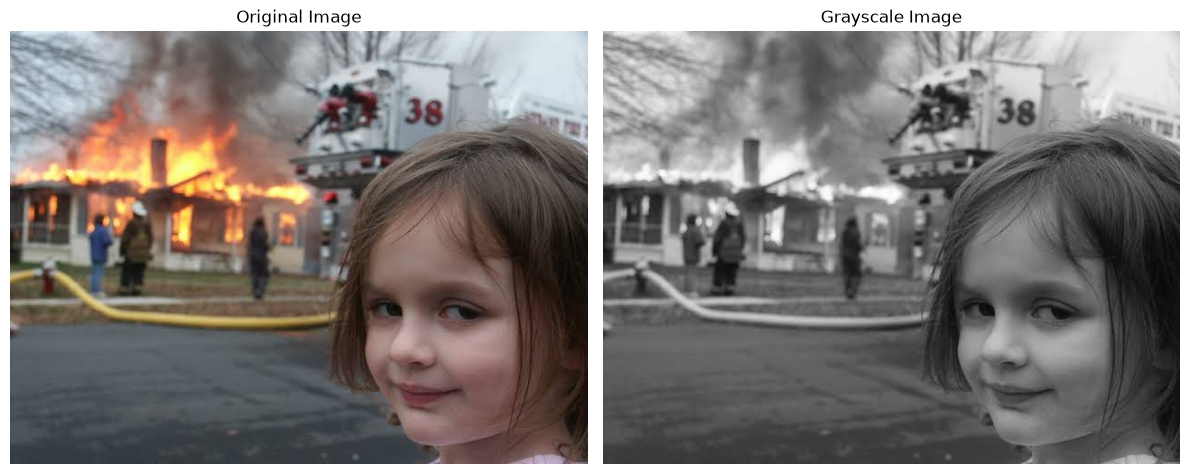

In [2]:
image_path = "../assets/input/sample.jpg"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### 3. Apply Gaussian Blur


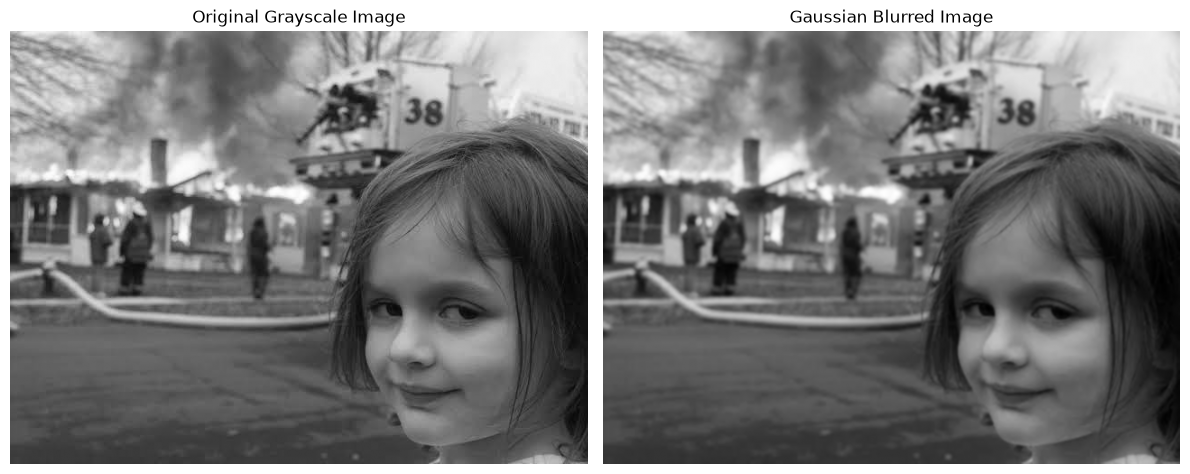

In [3]:
# Apply Gaussian smoothing
blurred_image = cv2.GaussianBlur(
    gray_image,
    (5, 5),
    sigmaX=1.0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_image, cmap="gray")
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### 4. Generate the Unsharp Mask


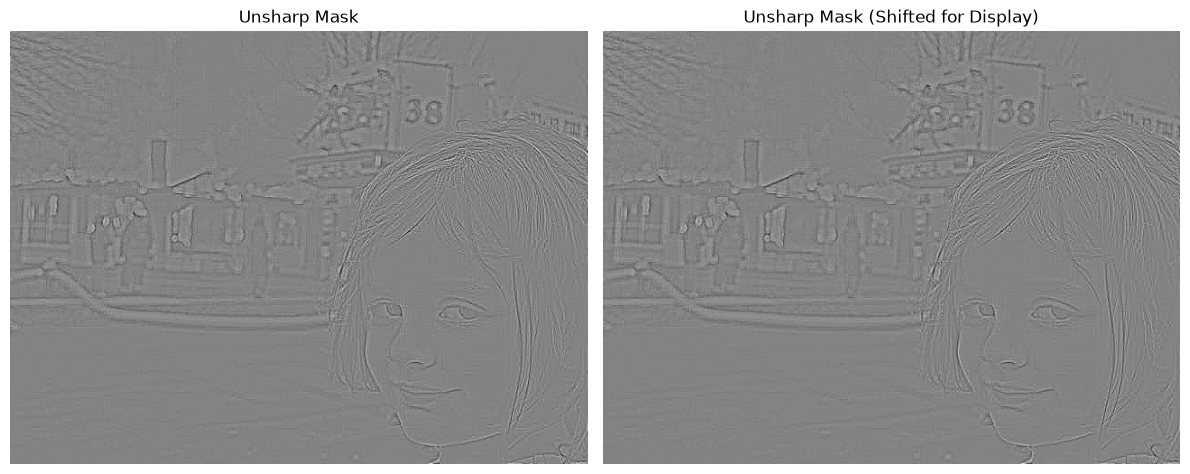

In [4]:
# Convert images to float32
original_float = gray_image.astype(np.float32)
blurred_float = blurred_image.astype(np.float32)

# Calculate the high-frequency mask
unsharp_mask = original_float - blurred_float

# Display the mask with shifted intensity values
mask_display = np.clip(unsharp_mask + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(unsharp_mask, cmap="gray")
plt.title("Unsharp Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_display, cmap="gray")
plt.title("Unsharp Mask (Shifted for Display)")
plt.axis("off")

plt.tight_layout()
plt.show()

### 5. Apply Unsharp Masking


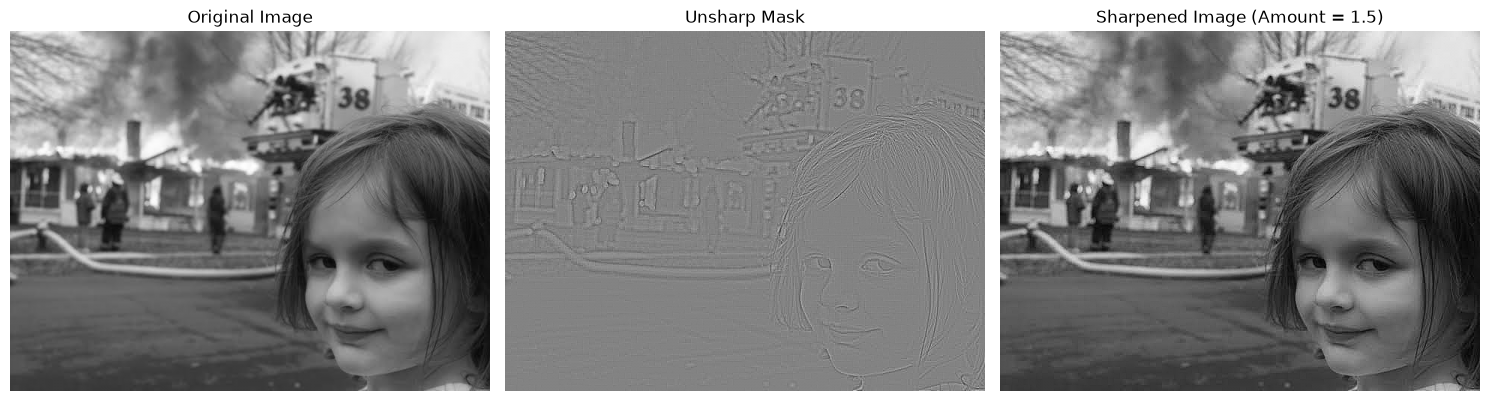

In [5]:
# Sharpening strength
amount = 1.5

# Add the scaled mask to the original image
sharpened_image = original_float + amount * unsharp_mask

# Clip values to the valid intensity range
sharpened_image = np.clip(sharpened_image, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask_display, cmap="gray")
plt.title("Unsharp Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened_image, cmap="gray")
plt.title(f"Sharpened Image (Amount = {amount})")
plt.axis("off")

plt.tight_layout()
plt.show()

### 6. Compare Different Sharpening Strengths


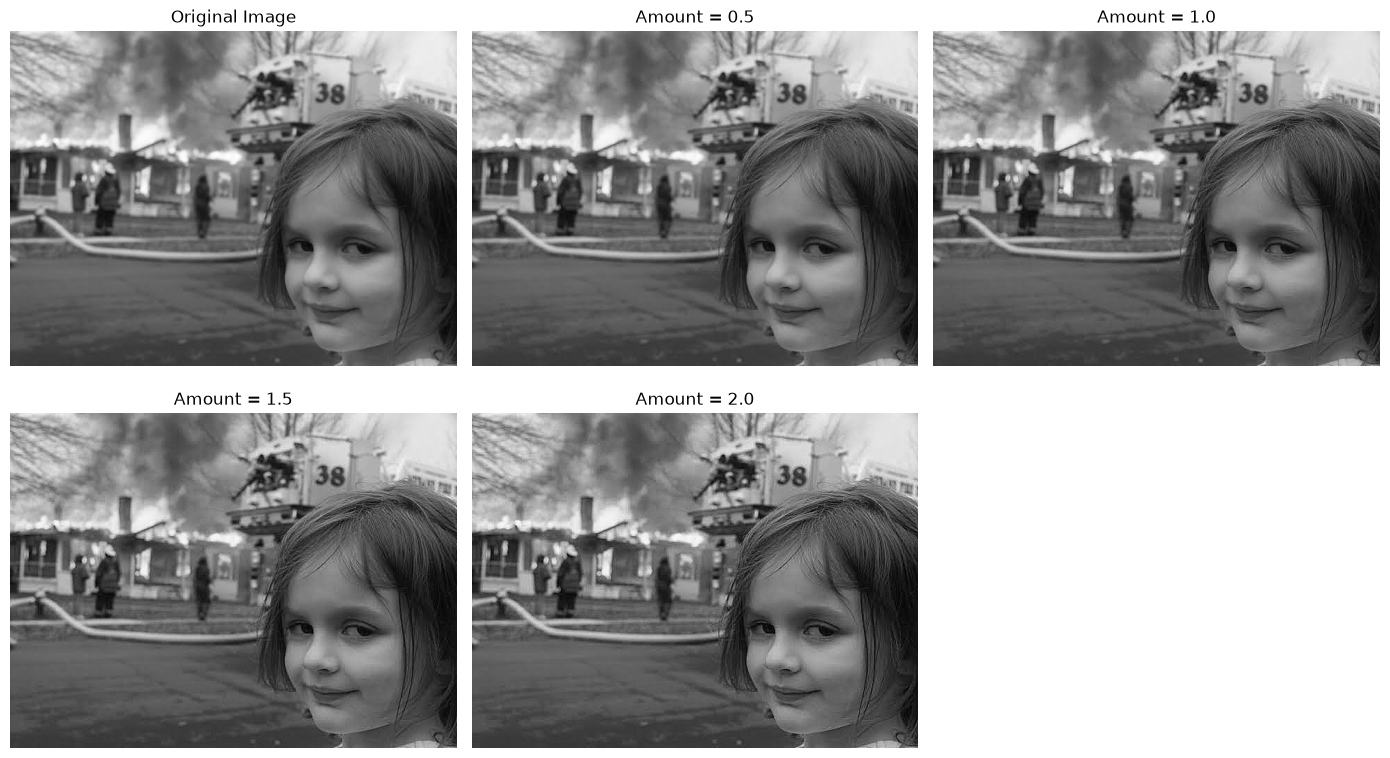

In [6]:
amounts = [0.5, 1.0, 1.5, 2.0]

plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

for index, amount in enumerate(amounts, start=2):
    result = original_float + amount * unsharp_mask
    result = np.clip(result, 0, 255).astype(np.uint8)

    plt.subplot(2, 3, index)
    plt.imshow(result, cmap="gray")
    plt.title(f"Amount = {amount}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### 7. Apply Unsharp Masking to the Color Image

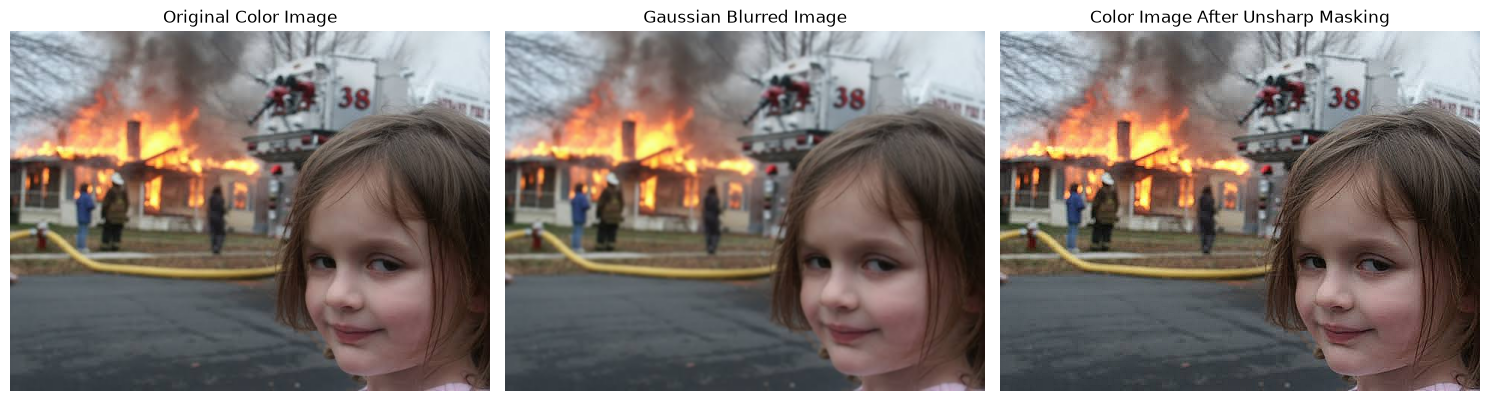

In [7]:
# Blur the original color image
blurred_color = cv2.GaussianBlur(
    rgb_image,
    (5, 5),
    sigmaX=1.0
)

# Convert to float32 for calculations
original_color_float = rgb_image.astype(np.float32)
blurred_color_float = blurred_color.astype(np.float32)

# Calculate the color unsharp mask
color_mask = original_color_float - blurred_color_float

# Apply unsharp masking
amount = 1.5
sharpened_color = original_color_float + amount * color_mask

# Clip and convert to uint8
sharpened_color = np.clip(sharpened_color, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred_color)
plt.title("Gaussian Blurred Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened_color)
plt.title("Color Image After Unsharp Masking")
plt.axis("off")

plt.tight_layout()
plt.show()

### 8. Verify the Results

In [8]:
print("Original image shape:", gray_image.shape)
print("Blurred image shape:", blurred_image.shape)
print("Unsharp mask shape:", unsharp_mask.shape)
print("Sharpened image shape:", sharpened_image.shape)

print("\nUnsharp mask minimum:", np.min(unsharp_mask))
print("Unsharp mask maximum:", np.max(unsharp_mask))

print("\nOriginal intensity range:",
      np.min(gray_image), "to", np.max(gray_image))

print("Sharpened intensity range:",
      np.min(sharpened_image), "to", np.max(sharpened_image))

Original image shape: (480, 640)
Blurred image shape: (480, 640)
Unsharp mask shape: (480, 640)
Sharpened image shape: (480, 640)

Unsharp mask minimum: -39.0
Unsharp mask maximum: 37.0

Original intensity range: 1 to 246
Sharpened intensity range: 0 to 255
